# ROC Curve

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots a classifier's true-positive rate against its false-positive rate at every decision threshold. The area under the curve (AUC) summarises discrimination independently of the threshold.

## When to use

- Compare the discriminative ability of diagnostic tests or ML classifiers
- Choose an operating threshold that trades sensitivity against specificity
- Use when classes are reasonably balanced

## Avoid when

- Positives are rare (ROC looks optimistic; use a precision–recall curve)
- You care about calibrated probabilities rather than ranking (use a calibration plot)

## Alternatives

- Precision–recall curve
- Calibration plot
- Confusion matrix at a chosen threshold

## Design tips

- Always draw the chance diagonal and put the AUC in the legend
- Use a square aspect ratio so both axes read the same

## Example

Two models (logistic regression, random forest) predicting a binary outcome on a held-out test set.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score

### Data

In [2]:
X, y = make_classification(n_samples=3000, n_features=20, n_informative=6, weights=[0.7],
                           flip_y=0.05, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
models = {"Logistic regression": LogisticRegression(max_iter=1000),
          "Random forest": RandomForestClassifier(n_estimators=300, random_state=0)}
scores = {name: m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for name, m in models.items()}
df = pd.DataFrame({"y_true": y_te, **scores})
df.head()

,y_true,Logistic regression,Random forest
0,1,0.807799,0.863333
1,0,0.115618,0.063333
2,1,0.811741,0.763333
3,1,0.119430,0.550000
4,1,0.968080,0.753333


### Plot

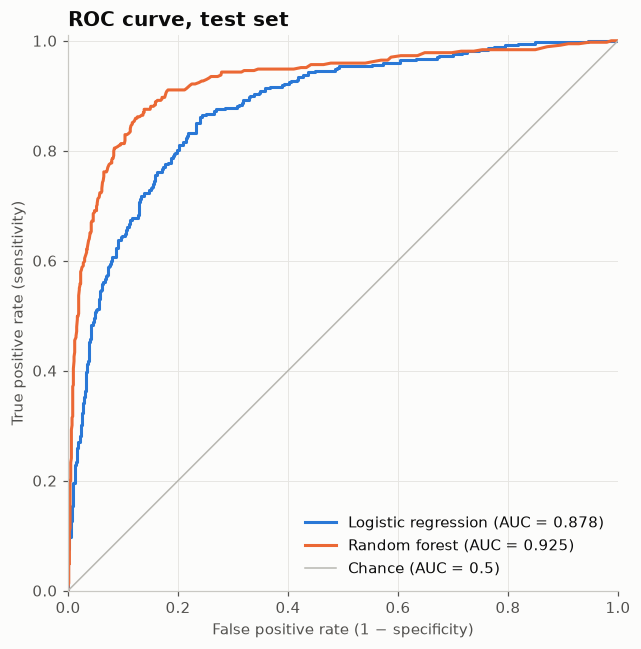

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
for i, name in enumerate(scores):
    fpr, tpr, _ = roc_curve(df["y_true"], df[name])
    ax.plot(fpr, tpr, color=PALETTE[i], label=f"{name} (AUC = {roc_auc_score(df['y_true'], df[name]):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1, label="Chance (AUC = 0.5)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect("equal")
ax.set_title("ROC curve, test set")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

The closer a curve bows toward the top-left corner, the better the model separates the classes. The diagonal is a coin flip.

## Try it with real data

**Source:** sklearn.datasets.load_breast_cancer() — Wisconsin diagnostic breast cancer, 569 tumours (malignant = positive), bundled with scikit-learn

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
bc = load_breast_cancer()
X, y = bc.data, 1 - bc.target                       # 1 = malignant
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)

models = {"Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "Random forest": RandomForestClassifier(n_estimators=300, random_state=0)}
scores = {name: m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for name, m in models.items()}
df = pd.DataFrame({"y_true": y_te, **scores})
df.head()

,y_true,Logistic regression,Random forest
0,0,0.000271,0.063333
1,0,0.002106,0.003333
2,0,0.187818,0.466667
3,1,0.999851,0.996667
4,1,0.999995,1.000000


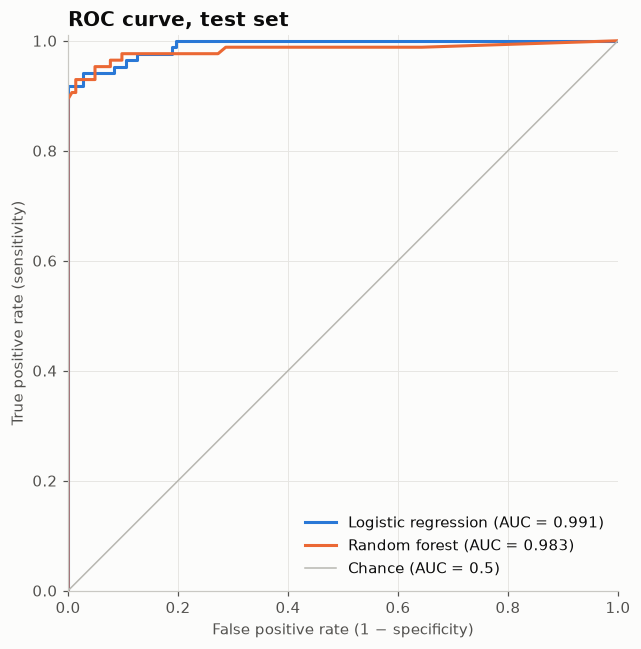

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
for i, name in enumerate(scores):
    fpr, tpr, _ = roc_curve(df["y_true"], df[name])
    ax.plot(fpr, tpr, color=PALETTE[i], label=f"{name} (AUC = {roc_auc_score(df['y_true'], df[name]):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1, label="Chance (AUC = 0.5)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect("equal")
ax.set_title("ROC curve, test set")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

---
Standalone script: [`roc_curve.py`](roc_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)